# Licencia, contrato, partición y prueba: cómo se construye un caso desde un archivo con licencia

**Pregunta:** Cuando un archivo público entra al proceso de datos, ¿qué garantiza cada una de sus cuatro etapas (una licencia y un hash, un contrato, una partición sin fugas, una fila de prueba), y con cuántos incumplimientos deja de valer algo la última garantía?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebooks 01 a 04 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- leer una fuente del registro y decir qué casos pueden leerla y si se puede publicar un documento derivado de ella;
- leer el hash que fija el manifiesto de licencias para un archivo con licencia, la regla con que la etapa rechaza un archivo que difiere de él y lo que dice la etapa cuando el archivo no está;
- decir qué aceptó, rechazó o ignoró el contrato 1 en la muestra alemana confirmada de 50 solicitantes, y leer las declaraciones confirmadas de sus ocho familias;
- partir un archivo con la partición estratificada y mostrar, frente a una partición aleatoria simple, por qué la muestra reservada conserva la tasa de incumplimiento;
- correr la batería de la etapa de evaluación y leer una fila de prueba campo por campo frente al contrato `test-result` documentado;
- seguir el linaje de licencias desde el registro hasta el bloque de procedencia de un documento confirmado, y decir qué comparte entre casos el sobre de modelos;
- hallar el número de incumplimientos bajo el cual el caso deja de valer la pena, y aplicar las mismas revisiones a un archivo propio.

## Preparación

Instala el entorno fijado una vez, en un entorno virtual, con el comando habitual:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 pandas==3.0.6 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Este notebook importa además las cuatro etapas del proceso de datos del producto (`pipeline.stages.ingest`, `split`, `evaluate` y `export`) y algunos de sus lectores. El proceso de datos son scripts sueltos y no un paquete, así que la celda siguiente pone `data-pipeline/` en la ruta de importación y los importa desde allí: un solo lector para el proceso, las pruebas y estos notebooks, nunca una copia. El notebook lee solo archivos confirmados: nunca lee la raíz de datos y nunca escribe un archivo. La celda imprime la versión de cada paquete.

In [1]:
# Pone el proceso de datos en la ruta de importación, importa sus etapas y el motor, e imprime las versiones
import hashlib
import importlib.metadata as md
import inspect
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc
from scipy.stats import norm
from sklearn.model_selection import train_test_split

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c01_features as feat
from pipeline.core import lineage
from pipeline.io import fetch as fetching, readers
from pipeline.io import sources as registry
from pipeline.io.contract import validate
from pipeline.stages import evaluate, export, ingest, split


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "pandas", "scikit-learn", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2


## Datos

El caso que seguimos es C01 (PD de crédito minorista) y el archivo es su segunda fuente, los datos de German Credit.

- **Propietario y licencia:** Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data. Clase de licencia `mirror-allowed` (CC BY 4.0, https://creativecommons.org/licenses/by/4.0/).
- **Contenido:** 1.000 solicitantes de crédito, 20 atributos y un desenlace bueno o malo, 300 de ellos malos. Es el gemelo de muestra pequeña del archivo de tarjetas de Taiwán que el caso C01 también lee.
- **Archivo detrás del caso, que aquí no se lee:** `statlog+german+credit+data.zip` (29.607 bytes), guardado en `raw/uci-german/` bajo la raíz de datos. No está en el repositorio y este notebook nunca lo lee. Quien tiene la licencia lo descarga y hornea el caso con los dos comandos siguientes, que el notebook muestra y nunca corre. Lo que el notebook lee en cambio está confirmado: la entrada del manifiesto del archivo, la muestra de 50 solicitantes del gemelo alemán confirmado, sus conteos de partición y sus filas de batería.

  ```bash
  python data-pipeline/fetch.py uci-german --data-root <tu raíz de datos>
  python data-pipeline/run.py C01 --output <una carpeta de prueba>
  ```

- **Por qué no el archivo de Taiwán:** es una hoja de cálculo que necesita el lector `xlrd`, que el entorno de los notebooks no fija. El archivo alemán es texto plano y pasa por las mismas cuatro etapas.
- **Documentos confirmados que se leen** (rutas desde la raíz del repositorio): `data-pipeline/config/sources.json`, `data-pipeline/config/licences.json`, `data/sources/manifest.json`, `data/derived/contract/index.json`, `data/derived/contract/scored_sample.json`, `docs/contracts/examples/common.test-result.json` con su esquema, `data/derived/C01/german-twin.json`, `data/derived/C01/models-german.json`, `data/derived/C22/models-generators.json` y el esquema del sobre de modelos.

## Método

Un caso es una función de un archivo fuente a un documento, y el proceso de datos corta esa función en cuatro etapas, cada una con una garantía que un lector posterior puede revisar. `ingest` deja que el registro, el hash fijado y el contrato 1 decidan qué puede entrar. `split` corta los registros para que nada se filtre de la muestra reservada al ajuste. `evaluate` corre las pruebas del motor, bajo una política, sobre la muestra reservada. `export` valida el documento contra su esquema y lo escribe con su linaje. El notebook recorre las cuatro con el caso alemán confirmado, corre cada función de etapa sobre una muestra confirmada, lee en cada etapa el documento confirmado que la rige, y termina preguntando dónde la cadena deja de informar.

### Paso 1: el registro decide si un caso puede leer una fuente

`data-pipeline/config/sources.json` es el registro de fuentes (contrato `source-registry`): cada fuente de datos que conoce el producto, con las palabras del propio editor sobre su licencia, su clase de redistribución y los casos que pueden leerla. `registry.load()` lo lee y lo revisa, y `assert_case_inputs` hace la pregunta que el proceso no puede errar: ¿puede este caso leer esta fuente? La celda siguiente carga el registro y cuenta sus fuentes por clase.

fuentes del registro: 58 | legibles por un caso: 41


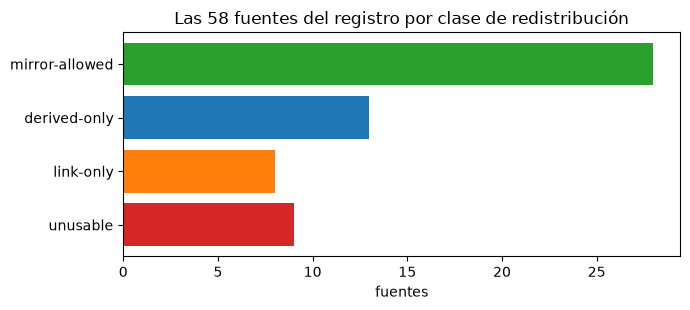

In [2]:
# Carga y revisa el registro de fuentes, y cuenta sus fuentes por clase de redistribución
sources = registry.load()
by_class = pd.Series(Counter(s.klass for s in sources.values()), name="fuentes").reindex(registry.CLASSES)
print("fuentes del registro:", len(sources), "| legibles por un caso:", sum(s.readable for s in sources.values()))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(by_class.index, by_class.values, color=["tab:green", "tab:blue", "tab:orange", "tab:red"])
ax.invert_yaxis()
ax.set_xlabel("fuentes")
ax.set_title(f"Las {len(sources)} fuentes del registro por clase de redistribución")
fig.tight_layout()
plt.show()

El registro tiene 58 fuentes. Veintiocho son `mirror-allowed`, cuyas filas crudas pueden confirmarse en el repositorio. Trece son `derived-only`, que un caso puede leer y cuyos resultados derivados puede publicar mientras las filas quedan fuera del repositorio. Ocho son `link-only` y nueve `unusable`: un caso puede enlazarlas y nunca leerlas. Cuarenta y una de las 58, las dos primeras barras, son entonces legibles por un caso. La figura da la situación de licencias de las entradas del producto de un vistazo. No muestra en detalle lo que prohíbe cada clase, que está escrito en el campo `licence` de cada entrada, y nada dice de si una fuente sigue en línea.

In [3]:
# Hace al registro tres preguntas que un caso no puede errar: una fuente listada, la de otro caso, una solo enlazable
link_only = next(s.id for s in sources.values() if s.klass == "link-only")
questions = [("C01", "uci-german"), ("C05", "uci-german"), ("C01", link_only)]
answers = []
for case, source in questions:
    try:
        registry.assert_case_inputs(case, [source], registry=sources)
        answers.append({"caso": case, "fuente": source, "respuesta": "puede leerla"})
    except registry.LicenceError as refusal:
        answers.append({"caso": case, "fuente": source, "respuesta": str(refusal)})
pd.DataFrame(answers)

,caso,fuente,respuesta
0,C01,uci-german,puede leerla
1,C05,uci-german,C05: uci-german does not list C05 among its ca...
2,C01,kaggle-gmsc,C01: kaggle-gmsc is link-only; it may be linke...


El registro responde las tres preguntas de tres maneras. El caso C01 puede leer `uci-german`, porque la fuente lista a C01 entre sus casos. El caso C05 no puede: la respuesta dice que `uci-german` no lista a C05 y que primero hay que actualizar el registro, de modo que un uso nuevo de una fuente es un cambio de registro que un revisor ve antes de que se mueva un solo dato. Y C01 no puede leer `kaggle-gmsc`, una fuente solo enlazable, que se puede enlazar y nunca leer. La tabla muestra el texto de los rechazos, que es lo que un desarrollador encuentra en un registro de fallos. No muestra quién decide qué casos lista una fuente; lo decide quien agrega el caso y edita el registro en el mismo cambio.

### Paso 2: el manifiesto de licencias fija los bytes

El registro dice si una fuente puede leerse; el manifiesto de licencias `data/sources/manifest.json` dice qué bytes se leyeron (contrato `licence-manifest`). Cada entrada copia del registro las palabras de licencia del editor, la clase y la atribución en el momento de la descarga, y agrega la lista de archivos con su nombre, URL, tamaño, fecha de descarga y hash SHA-256. Solo lo escribe `data-pipeline/fetch.py`. La celda siguiente imprime la entrada de `uci-german`, campo por campo.

In [4]:
# Una entrada del manifiesto de licencias, campo por campo: las palabras del editor, la clase y el archivo fijado
manifest = fetching.load_manifest()
entry = manifest["sources"]["uci-german"]
pinned = entry["files"][0]
fields = {key: entry[key] for key in ("publisher", "class", "access", "licence", "attribution")}
fields.update({f"archivo {key}": pinned[key] for key in ("name", "bytes", "retrieved")})
fields["archivo sha256"] = pinned["sha256"][:16] + "..."
pd.Series(fields, name="uci-german").to_frame()

,uci-german
publisher,UCI Machine Learning Repository / H. Hofmann
class,mirror-allowed
access,http
licence,This dataset is licensed under a Creative Comm...
attribution,"Hofmann, H. (1994). Statlog (German Credit Dat..."
archivo name,statlog+german+credit+data.zip
archivo bytes,29607
archivo retrieved,2026-10-05
archivo sha256,e12d9d5def6845c0...


La entrada da el editor (UCI y H. Hofmann), la clase `mirror-allowed`, el método de acceso `http`, la frase de licencia, la atribución que se debe citar y un archivo: `statlog+german+credit+data.zip`, 29.607 bytes, descargado el 2026-10-05, con un hash SHA-256 que empieza con `e12d9d5def6845c0`. Las nueve filas son toda la procedencia de la entrada cruda. No dan el contenido del archivo, y eso es lo que compara la etapa. Acepta un archivo $f$ solo si su hash es igual al que fija el manifiesto,

$$\mathrm{aceptar}(f) \iff \mathrm{SHA\text{-}256}(f) = h_{\mathrm{fijado}}$$

donde $f$ es el contenido en bytes del archivo y $h_{\mathrm{fijado}}$ el hash de 64 dígitos del manifiesto (NIST FIPS 180-4, https://doi.org/10.6028/NIST.FIPS.180-4). La celda siguiente calcula el hash del archivo en disco y pone el resultado junto a la fijación. Luego fija un valor errado en una copia del manifiesto y deja que la etapa lea de nuevo el mismo archivo, sin cambios.

In [5]:
# Calcula el hash de un texto confirmado, muestra la regla de la etapa y lee lo que dice sin el archivo con licencia
digest = hashlib.sha256(entry["licence"].encode("utf-8")).hexdigest()
print(
    "sha256 de la frase de licencia de la entrada del manifiesto:", digest[:16], "| fijación del archivo alemán:",
    pinned["sha256"][:16]
)
print(
    "una fijación tiene", len(pinned["sha256"]), "caracteres hexadecimales, el hash de",
    len(bytes.fromhex(pinned["sha256"])), "bytes"
)
rule = [line.strip() for line in inspect.getsource(ingest.raw_file).splitlines()
    if "digest" in line and "pinned[name]" in line]
print("la regla de la etapa:", rule)
try:
    ingest.raw_file("uci-german", pinned["name"], ROOT / "data" / "absent-data-root")
except ingest.IngestError as refusal:
    print("sin el archivo con licencia la etapa dice:", str(refusal).split(" is missing: ")[1])

sha256 de la frase de licencia de la entrada del manifiesto: e20a8d147234ab62 | fijación del archivo alemán: e12d9d5def6845c0
una fijación tiene 64 caracteres hexadecimales, el hash de 32 bytes
la regla de la etapa: ['if digest != pinned[name]:']
sin el archivo con licencia la etapa dice: fetch it with data-pipeline/fetch.py uci-german --data-root <root>


La fijación del archivo alemán empieza con `e12d9d5def6845c0`: una fijación son 64 caracteres hexadecimales, el resumen SHA-256 de 32 bytes (NIST, 2015). La celda calcula el mismo resumen sobre un texto confirmado, la frase de licencia de la entrada del manifiesto, solo para mostrar el cálculo. La regla de la etapa es una línea, `if digest != pinned[name]`: calcula el hash del archivo descargado y lo rechaza cuando el resumen no es el fijado. Sin el archivo con licencia, que es la situación de un clon de este repositorio, la etapa no adivina: dice que se descargue con `data-pipeline/fetch.py uci-german --data-root <root>`. La guardia es brusca a propósito. Si el editor reemplazó el archivo, o una descarga quedó cortada, los documentos derivados de él ya no derivarían de lo que registra el manifiesto, y ninguna etapa posterior podría notarlo. Quien tiene la licencia corre los comandos de la sección Datos; este notebook nunca lo hace. La celda muestra la regla, la fijación y el mensaje, y no muestra el rechazo de un hash errado, que necesita el archivo. Tampoco muestra que el archivo fijado sea el que el editor quiso; eso solo lo pueden decir la URL y la fecha de descarga del manifiesto.

### Paso 3: el contrato 1 decide qué registros entran

Tras el hash, la etapa pasa los registros del editor por el contrato 1, que interpreta cada valor según su tipo declarado y acepta, rechaza, señala o excluye cada registro (el notebook 04 lo mostró con una muestra tuya). Sus declaraciones están confirmadas. `data/derived/contract/index.json` lista las ocho familias (contrato `contract-index`), y un documento por familia declara sus campos, sus reglas y sus parámetros (contrato `contract-family`). La celda siguiente lee el índice, abre cada familia y cuenta lo que declara.

In [6]:
# Las declaraciones confirmadas del contrato 1: el índice de sus ocho familias y lo que declara cada una
index = read_json("data/derived/contract/index.json")
declared = []
for item in index["families"]:
    family = read_json(f"data/derived/contract/{item['path']}")
    declared.append(
        {"familia": item["family"], "campos": len(family["fields"]), "reglas": len(family["rules"]),
         "campos abiertos": family["open_fields"], "usada por": family["used_by"]["es"][:48]}
    )
pd.DataFrame(declared)

,familia,campos,reglas,campos abiertos,usada por
0,scored_sample,9,2,True,Todo caso de PD y de ML: una fila por deudor o c
1,loan_panel,14,6,False,"PD de vida completa, etapas y PCE de IFRS 9, LGD"
2,rating_history,3,3,False,"Matrices de transición, tasas de incumplimiento"
3,market_series,4,2,False,"VaR y ES, pruebas retrospectivas y ventanas de e"
4,curve,4,2,False,"IRRBB, VaR de tasas, simulación de exposición: u"
5,balance_sheet,12,1,False,"IRRBB y liquidez: una fila por partida, moneda y"
6,loss_events,6,3,False,LDA y SMA de riesgo operacional: una fila por ev
7,macro_path,6,2,False,"Pruebas de tensión, escenarios de IFRS 9, satéli"


Hay ocho familias, una por cada clase de entrada que traen los casos: la muestra puntuada (9 campos y 2 reglas, con campos abiertos porque cada caso agrega sus propias variables), el panel de préstamos (14 campos, 6 reglas), la historia de calificaciones (3 y 3), la serie de mercado (4 y 2), la curva (4 y 2), el balance (12 y 1), los eventos de pérdida (6 y 3) y la trayectoria macro (6 y 2). El caso que seguimos usa la primera. La tabla muestra cuánto pide cada familia a una fuente: una historia de calificaciones necesita tres campos y un panel de préstamos catorce. No muestra las reglas mismas; cada documento de familia enuncia cada regla con su alcance, su política (rechazar, señalar o excluir) y su enunciado en inglés y en español. La celda siguiente corre el contrato 1, la revisión dentro de la etapa de ingesta, sobre los 50 solicitantes de la muestra alemana confirmada con la familia `scored_sample` y los campos adicionales propios del caso.

In [7]:
# Corre el contrato 1, la revisión dentro de la etapa de ingesta, sobre los 50 solicitantes de la muestra alemana
# confirmada
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
records = [
    {"id": ident, "observation_date": readers.GERMAN_OBSERVATION_DATE, "target": target,
     **{name: values[k] for name, values in sample["inputs"].items()}}
    for k, (ident, target) in enumerate(zip(sample["ids"], sample["targets"]))
]
report = validate("scored_sample", records, extra_fields=feat.GERMAN_FIELDS)
frame = pd.DataFrame(report.accepted)
print("contrato 1:", report.counts())
print("columnas ignoradas:", report.ignored_columns)
print("solicitantes:", len(frame), "| incumplimientos:", int(frame["target"].sum()))
print("tasa de incumplimiento:", round(float(frame["target"].mean()), 3))

contrato 1: {'input': 50, 'accepted': 50, 'rejected': 0, 'flagged': 0, 'excluded': 0}
columnas ignoradas: []
solicitantes: 50 | incumplimientos: 12
tasa de incumplimiento: 0.24


El contrato 1 devuelve 50 registros aceptados de 50 leídos, ninguno rechazado, señalado o excluido, de modo que la muestra alemana confirmada es una entrada limpia para el contrato. No se ignora ninguna columna, porque la muestra trae solo las entradas del modelo; las columnas ignoradas son lo que el informe lista cuando una fuente trae más de lo que el caso declara, por ejemplo los atributos protegidos, que el lector conserva solo para las pruebas de equidad. El marco tiene 50 solicitantes y 12 incumplimientos, una tasa de incumplimiento de 0,24, bajo el 0,3 del archivo completo que usa el paso siguiente, porque 50 solicitantes son un corte. Este es el objeto que toma cada etapa posterior: una tabla de registros aceptados en el orden de entrada y un informe de lo que pasó con el resto. Un informe con rechazos es lo primero que se lee en un caso nuevo, porque todo lo que sigue se calcula solo con las filas aceptadas.

### Paso 4: una partición que no puede filtrar

La segunda etapa corta los registros aceptados en tres partes disjuntas: una parte de entrenamiento donde se ajustan los modelos, una parte de calibración donde se ajusta todo lo que va sobre un modelo (un mapa de puntaje, el AUC inicial) y una muestra reservada bloqueada que se abre una sola vez. `split.stratified_split` toma las etiquetas y una semilla, aparta la fracción reservada $h$ (30 por ciento por defecto) y luego la fracción de calibración del resto (20 por ciento), estratificando cada vez por la marca de incumplimiento, y agrega pliegues estratificados repetidos dentro de la parte de entrenamiento para cada elección que hace un método. El número de incumplimientos de la reservada queda entonces fijo por construcción,

$$d_h = \mathrm{round}\,(h\,D)$$

donde $D$ es el número de incumplimientos del archivo, así que la reservada conserva la tasa de incumplimiento del archivo salvo un registro. La partición es una función pura de las etiquetas y la semilla (scikit-learn, https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html). El archivo con licencia no se lee aquí, y la partición depende solo de las etiquetas, así que la celda siguiente rearma un vector de etiquetas con los conteos del documento de modelos confirmado (1.000 solicitantes y 300 incumplimientos, puestos en posiciones al azar con una semilla fija), lo parte con la semilla 42, lista qué tiene cada parte y compara los tamaños y los incumplimientos con la partición confirmada.

In [8]:
# Rearma las etiquetas del archivo con los conteos de la partición confirmada, las parte con la partición
# estratificada y lista cada parte
committed_split = read_json("data/derived/C01/models-german.json")["fit"]["split"]
names = ("train", "calibration", "holdout")
n_file = sum(committed_split[name]["n"] for name in names)
d_file = sum(committed_split[name]["defaults"] for name in names)
y_all = np.zeros(n_file, dtype=int)
y_all[np.random.default_rng(0).choice(n_file, size=d_file, replace=False)] = 1
parts = split.stratified_split(y_all, seed=42)
summary = parts.summary(y_all)
table = pd.DataFrame({name: summary[name] for name in names}).T
table[["n", "defaults"]] = table[["n", "defaults"]].astype(int)
print("solicitantes:", n_file, "| incumplimientos:", d_file, "| tasa de incumplimiento:", round(float(y_all.mean()), 3))
print("partes disjuntas:", parts.disjoint(), "| pliegues dentro de la parte de entrenamiento:", len(parts.folds))
print("mismos tamaños e incumplimientos que la partición confirmada:", all(
    summary[name][key] == committed_split[name][key] for name in names for key in ("n", "defaults")))
needed = cal.critical_default_count(len(parts.holdout), float(y_all.mean()), q=0.95)
print("incumplimientos que necesita en la reservada una prueba de nivel de 95% para objetar:", needed)
print("incumplimientos esperados:", summary["holdout"]["defaults"])
table

solicitantes: 1000 | incumplimientos: 300 | tasa de incumplimiento: 0.3
partes disjuntas: True | pliegues dentro de la parte de entrenamiento: 10
mismos tamaños e incumplimientos que la partición confirmada: True
incumplimientos que necesita en la reservada una prueba de nivel de 95% para objetar: 104
incumplimientos esperados: 90


,n,defaults,default_rate
train,560,168,0.3
calibration,140,42,0.3
holdout,300,90,0.3


La partición tiene 560 registros de entrenamiento, 140 de calibración y 300 reservados, con 168, 42 y 90 incumplimientos: una tasa de incumplimiento de exactamente 0,3 en cada parte, la tasa del archivo. Los tamaños y los incumplimientos son iguales a los de la partición confirmada (`True`), las partes son disjuntas (`True`) y la parte de entrenamiento lleva 10 pliegues, 5 por cada una de 2 repeticiones. La tabla es lo que un revisor pide de una partición antes de mirar cualquier modelo: que nada se comparta entre las partes y que cada una tenga incumplimientos suficientes para probar. Noventa incumplimientos en la reservada es cómodo, y el motor dice cuán cómodo: su `critical_default_count` pone el punto en que una prueba de nivel de 95 por ciento objeta en 104 incumplimientos en una reservada de 300 registros con una tasa de incumplimiento de 0,3, un exceso de 16 por ciento sobre los 90 esperados. El barrido del final del notebook muestra cómo se encoge ese conteo. La tabla no muestra que las variables estén libres de fuga, por ejemplo una columna calculada después de la fecha de incumplimiento; eso es propiedad del lector y del contrato, no de la partición.

¿Por qué estratificar? Una reservada aleatoria simple de $n_h$ registros entre $n$ sortea sus incumplimientos sin reemplazo, de modo que la tasa de incumplimiento de la reservada tiene la desviación estándar de un sorteo hipergeométrico,

$$\mathrm{sd}(\hat\pi_h) = \sqrt{\frac{\bar y\,(1-\bar y)}{n_h}\left(1 - \frac{n_h}{n}\right)}$$

donde $\bar y$ es la tasa de incumplimiento del archivo y el paréntesis es la corrección por población finita (https://en.wikipedia.org/wiki/Hypergeometric_distribution). Un modelo puntuado sobre una reservada que resulta rica en incumplimientos parece peor sin razón propia. La celda siguiente repite la partición con 300 semillas para cinco fracciones reservadas, una vez con la partición estratificada de la etapa y otra con una aleatoria simple, e imprime las cinco desviaciones estándar de cada una.

In [9]:
# La tasa de incumplimiento de la reservada en 300 semillas, con la partición estratificada y con una aleatoria
fractions = [0.05, 0.1, 0.2, 0.3, 0.5]
sd_stratified, sd_random, at_ten = [], [], {}
for fraction in fractions:
    stratified, plain = [], []
    for seed in range(300):
        held = split.stratified_split(y_all, seed=seed, holdout=fraction).holdout
        stratified.append(y_all[held].mean())
        _, held = train_test_split(np.arange(len(y_all)), test_size=fraction, random_state=seed)
        plain.append(y_all[held].mean())
    sd_stratified.append(np.std(stratified))
    sd_random.append(np.std(plain))
    if fraction == 0.1:
        at_ten = {"stratified": stratified, "random": plain}
print("desviación estándar de la tasa reservada, estratificada:", np.round(sd_stratified, 4))
print("desviación estándar de la tasa reservada, aleatoria:    ", np.round(sd_random, 4))

desviación estándar de la tasa reservada, estratificada: [0. 0. 0. 0. 0.]
desviación estándar de la tasa reservada, aleatoria:     [0.0624 0.0441 0.0304 0.0221 0.0139]


La primera línea es cero con toda fracción, como dice la construcción, y la segunda baja a medida que crece la reservada. La celda siguiente dibuja el caso de 10 por ciento como dos histogramas y las cinco desviaciones estándar de la partición aleatoria frente a la fórmula anterior, que imprime.

fórmula de la partición aleatoria: [0.0632 0.0435 0.029  0.0221 0.0145]


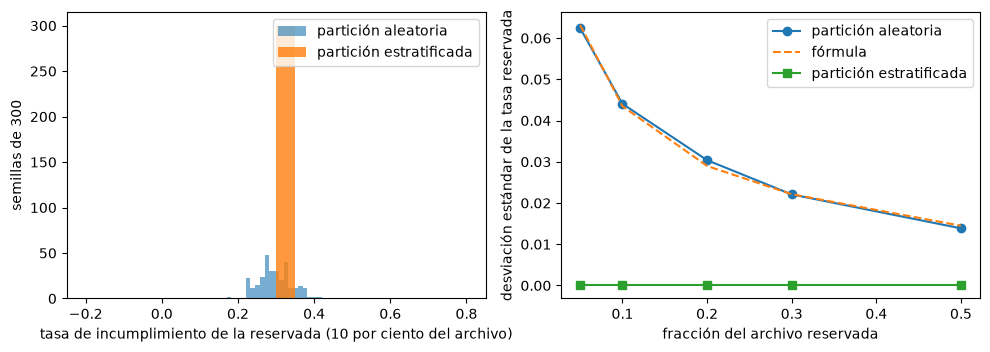

In [10]:
# Dibuja las dos dispersiones con 10 por ciento reservado y la de la partición aleatoria frente a la fórmula
rate = y_all.mean()
size = np.array(fractions) * len(y_all)
formula = np.sqrt(rate * (1 - rate) / size * (1 - size / len(y_all)))
print("fórmula de la partición aleatoria:", np.round(formula, 4))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.hist(at_ten["random"], bins=20, alpha=0.6, label="partición aleatoria")
left.hist(at_ten["stratified"], bins=20, alpha=0.8, label="partición estratificada")
left.set_xlabel("tasa de incumplimiento de la reservada (10 por ciento del archivo)")
left.set_ylabel("semillas de 300")
left.legend()
right.plot(fractions, sd_random, marker="o", label="partición aleatoria")
right.plot(fractions, formula, linestyle="--", label="fórmula")
right.plot(fractions, sd_stratified, marker="s", label="partición estratificada")
right.set_xlabel("fracción del archivo reservada")
right.set_ylabel("desviación estándar de la tasa reservada")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, con 10 por ciento del archivo reservado, la partición aleatoria reparte la tasa de incumplimiento de la reservada en una campana de desviación estándar 0,0441 en torno al 0,3 del archivo, y la estratificada es un solo pico en 0,3. A la derecha la desviación estándar de la partición aleatoria baja de 0,0624 con 5 por ciento reservado a 0,0139 con 50 por ciento, y sigue la fórmula (0,0632, 0,0435, 0,029, 0,0221 y 0,0145) con menos de 5 por ciento de diferencia. La partición estratificada está en cero con toda fracción. La figura muestra que la estratificación elimina una fuente de ruido que un evaluador atribuiría si no al modelo, y que el ruido de una partición simple es mayor justo donde las reservadas son pequeñas. No muestra que estratificar sea gratis: una reservada estratificada ya no es un sorteo aleatorio de la etiqueta, lo que es el diseño correcto para evaluar un modelo y el incorrecto para estimar la tasa base de una población nueva.

### Paso 5: la etapa de evaluación corre las pruebas del motor

`evaluate.battery` es la tercera etapa y no agrega ningún estadístico propio. Cada prueba es del motor, corrida bajo su política versionada; lo que decide la etapa es el diseño: qué muestra lee cada prueba, contra qué referencia compara cada prueba de estabilidad y en qué orden salen las filas. Toma las PD y los desenlaces de la reservada y, como referencias, las PD de entrenamiento (para el PSI), las PD y los desenlaces de calibración (para el AUC frente al inicial y la concentración de grados) y, cuando hay un campeón, sus PD para la prueba pareada de AUC. El notebook no necesita un modelo propio: el gemelo alemán confirmado tiene las filas de batería que la etapa produjo para el peldaño del scorecard sobre sus 300 solicitantes reservados, y una muestra de 50 solicitantes con la PD del scorecard. La celda siguiente lee ambas. A la etapa no le importa de dónde vienen las PD.

In [11]:
# Las entradas de la etapa de evaluación que tienen los documentos confirmados: las filas de la batería del
# scorecard y su muestra de 50
policy = default_policy()
rows = [row for row in twin["tests"] if row["model_id"] == "P1-scorecard"]
pd_sample, y_sample = np.array(sample["scorecard_pd"]), np.array(sample["targets"])
print(
    "filas de batería del scorecard en el documento confirmado:", len(rows),
    "| registros reservados detrás de ellas:", rows[0]["n"]
)
print(
    "solicitantes de la muestra:", len(y_sample), "| incumplimientos:", int(y_sample.sum()),
    "| PD media del scorecard:", round(float(pd_sample.mean()), 4)
)

filas de batería del scorecard en el documento confirmado: 24 | registros reservados detrás de ellas: 300
solicitantes de la muestra: 50 | incumplimientos: 12 | PD media del scorecard: 0.2601


La celda lee las 24 filas de batería del peldaño del scorecard, calculadas sobre 300 solicitantes reservados, y la muestra de 50 solicitantes con 12 incumplimientos y una PD media de 0,2601. La celda siguiente cuenta las filas confirmadas por semáforo, lista las pruebas, los valores p de las filas de cartera y las filas que no son verdes, y luego llama a la batería sobre la muestra: los primeros 25 solicitantes son la referencia del PSI y los últimos 25 se evalúan. Sin una parte de calibración no se corren el AUC frente al inicial ni la concentración de grados.

In [12]:
# Lee las filas de batería confirmadas, corre la batería de la etapa sobre la muestra y la compara con una llamada
# directa al motor
print("filas devueltas:", len(rows), "| por semáforo:", dict(Counter(row["light"] for row in rows)))
print("pruebas corridas:", sorted({row["test_id"] for row in rows}))
portfolio = {row["test_id"]: row["p_value"] for row in rows if row["segment"] == "portfolio"}
print("valores p de cartera:", {k: float(f"{v:.3g}") for k, v in portfolio.items() if v is not None})
amber = [(r["test_id"], r["segment"], round(r["p_value"], 4)) for r in rows if r["light"] in ("amber", "red")]
print("filas ámbar o rojas:", amber)
half = len(y_sample) // 2
sample_rows = evaluate.battery(
    "scorecard-sample", pd_sample[half:], y_sample[half:], pd_train=pd_sample[:half], pd_cal=None, y_cal=None,
    champion_pd=None, policy=policy,
)
print(
    "filas de la etapa sobre los últimos", len(y_sample) - half, "solicitantes:", len(sample_rows),
    "| pruebas corridas:", len({r["test_id"] for r in sample_rows})
)
direct = disc.disc_auc(pd_sample[half:], y_sample[half:], policy=policy)
stage_auc = next(row["metric"] for row in sample_rows if row["test_id"] == "disc.auc")
print("AUC en la fila de la etapa:", round(stage_auc, 6), "| AUC de una llamada directa:", round(direct.metric, 6))

filas devueltas: 24 | por semáforo: {'not_evaluated': 4, 'green': 20}
pruebas corridas: ['disc.auc', 'disc.auc_vs_initial', 'disc.ks', 'pd.binomial', 'pd.binomial_vasicek', 'pd.brier', 'pd.chi2_grades', 'pd.ece', 'pd.hosmer_lemeshow', 'pd.jeffreys', 'pd.spiegelhalter', 'rating.hhi', 'stability.psi']
valores p de cartera: {'disc.auc_vs_initial': 0.162, 'disc.ks': 1.72e-12, 'pd.jeffreys': 0.421, 'pd.binomial': 0.445, 'pd.binomial_vasicek': 0.461, 'pd.chi2_grades': 0.973, 'pd.hosmer_lemeshow': 0.876, 'pd.spiegelhalter': 0.407, 'stability.psi': 0.42, 'rating.hhi': 0.565}
filas ámbar o rojas: []
filas de la etapa sobre los últimos 25 solicitantes: 20 | pruebas corridas: 11
AUC en la fila de la etapa: 0.674603 | AUC de una llamada directa: 0.674603


El documento confirmado tiene 24 filas de 13 pruebas: 20 verdes y 4 sin evaluar, ninguna ámbar ni roja. Las pruebas son el AUC, el AUC frente al inicial, el estadístico de Kolmogorov-Smirnov, la prueba de Jeffreys (una fila por grado ocupado, 11, y una para la cartera, Brown, Cai y DasGupta 2001), las pruebas binomial y binomial ajustada por Vasicek, el chi-cuadrado sobre los grados, Hosmer-Lemeshow, Spiegelhalter, el puntaje de Brier, el error de calibración esperado, el PSI y la concentración de grados. Las cuatro filas sin semáforo son el AUC, el estadístico KS, el puntaje de Brier y el error de calibración, que la política por defecto deja sin puntos de corte (notebooks 02 y 03). Los valores p de cartera de las pruebas con color están lejos de los puntos de corte, el menor es 0,162 para el AUC frente al inicial; el 1,72e-12 de la fila de Kolmogorov-Smirnov pertenece a una prueba sin puntos de corte. La etapa corrida sobre la muestra devuelve 20 filas de 11 pruebas, las 13 menos las dos que necesitan una parte de calibración, y muestra lo que la etapa agrega al motor, que no es nada estadístico: el AUC de la fila de la etapa, 0,674603, es igual al AUC de una llamada directa al motor sobre los mismos arreglos, 0,674603. Ese AUC, de 25 solicitantes, está lejos del 0,7883 del documento confirmado con 300, una brecha cuyo tamaño es el tema de la última sección.

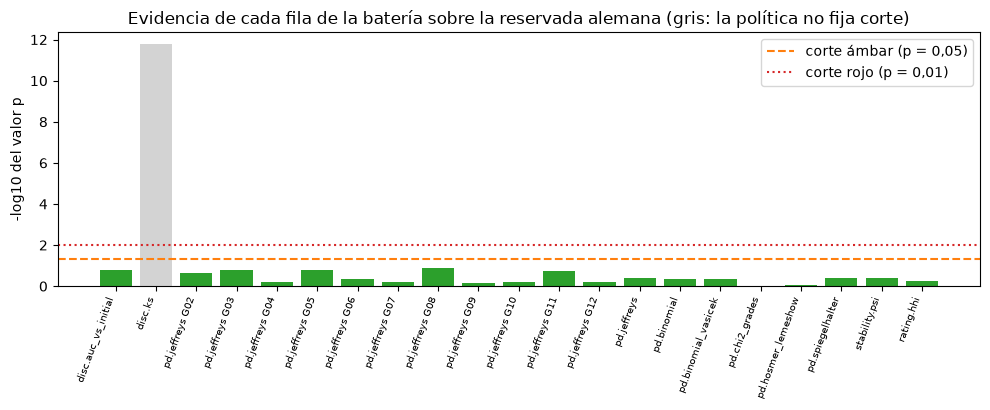

In [13]:
# Dibuja cada fila con valor p como menos el logaritmo base 10 de este, coloreada con el semáforo que dio la política
shades = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red", "not_evaluated": "lightgray"}
shown = [row for row in rows if row["p_value"] is not None]
names = [row["test_id"] + ("" if row["segment"] == "portfolio" else " " + row["segment"]) for row in shown]
heights = [-np.log10(max(row["p_value"], 1e-300)) for row in shown]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(range(len(shown)), heights, color=[shades[row["light"]] for row in shown])
ax.axhline(-np.log10(0.05), color="tab:orange", linestyle="--", label="corte ámbar (p = 0,05)")
ax.axhline(-np.log10(0.01), color="tab:red", linestyle=":", label="corte rojo (p = 0,01)")
ax.set_xticks(range(len(shown)))
ax.set_xticklabels(names, rotation=70, ha="right", fontsize=7)
ax.set_ylabel("-log10 del valor p")
ax.set_title("Evidencia de cada fila de la batería sobre la reservada alemana (gris: la política no fija corte)")
ax.legend()
fig.tight_layout()
plt.show()

Cada barra es menos el logaritmo base 10 del valor p de una fila, así que una barra más alta es evidencia más fuerte contra las PD, y su color es el semáforo que dio la política. Se dibujan las 21 filas que tienen valor p. Las filas de cartera son bajas y verdes: el nivel y el ajuste no se rechazan en la reservada. Ninguna barra cruza la línea ámbar; la barra con color más baja es la prueba de Jeffreys del grado G08, con un valor p de 0,1317, entre 12 filas de Jeffreys. La barra más alta es gris: el estadístico de Kolmogorov-Smirnov tiene un valor p de 1,72e-12, y la política no colorea nada para él, de modo que la barra más grande de la figura no lleva semáforo. La figura muestra que ninguna prueba con color rechaza este scorecard con 300 solicitantes y 90 incumplimientos. No muestra que el scorecard sea correcto: cuánto puede ver una prueba con ese tamaño es lo que mide la última sección.

### Paso 6: una fila de prueba es el contrato `test-result`

Cada fila que devuelve la batería tiene la misma forma, definida por el esquema `docs/contracts/schemas/common/test-result.schema.json` (contrato `test-result`) e ilustrada por un ejemplo documentado. El esquema exige 18 claves: la prueba y el modelo sobre el que se corrió, el segmento, el estadístico, el valor p y la métrica, la hipótesis nula y su alternativa, la política que coloreó la fila con sus dos puntos de corte y el semáforo, el tamaño de muestra y el número de eventos, un hash de las entradas, la referencia que define la prueba, notas libres y los extras de esa prueba. La celda siguiente pone el ejemplo documentado junto a la prueba de Jeffreys de nuestra reservada, llamada directamente al motor con los conteos de la reservada (la batería hace la misma llamada), con los valores largos cortados en 46 caracteres.

In [14]:
# El ejemplo documentado de una fila de prueba junto a una fila de nuestra batería: las mismas claves
example = read_json("docs/contracts/examples/common.test-result.json")
schema = read_json("docs/contracts/schemas/common/test-result.schema.json")
ours = next(r for r in rows if r["test_id"] == "pd.jeffreys" and r["segment"] == "portfolio")
both = pd.DataFrame({"ejemplo documentado": example, "nuestra fila": ours}).map(lambda value: str(value)[:46])
print("claves que exige el esquema:", len(schema["required"]), "| claves de nuestra fila:", len(ours))
print(
    "nuestra fila: n", ours["n"], "| incumplimientos", ours["n_events"], "| valor p", round(ours["p_value"], 4),
    "| semáforo", ours["light"]
)
both

claves que exige el esquema: 18 | claves de nuestra fila: 18
nuestra fila: n 300 | incumplimientos 90 | valor p 0.4206 | semáforo green


,ejemplo documentado,nuestra fila
test_id,pd.jeffreys,pd.jeffreys
model_id,E0-expert,P1-scorecard
segment,A,portfolio
statistic,0.0,0.3
p_value,0.193755529,0.420596273
metric,None,None
h0,the PD applied at the start of the period is g,the PD applied at the start of the period is g
alternative,the true PD exceeds the PD applied (underestim,the true PD exceeds the PD applied (underestim
policy_version,riskvalidation-default 2026.10.1,riskvalidation-default 2026.10.1
alpha_amber,0.05,0.05


Ambas columnas tienen las mismas 18 claves. El ejemplo es una PD experta probada con 100 deudores sin incumplimientos, un valor p de 0,1938 y un semáforo verde; el nuestro es el scorecard sobre los 300 solicitantes reservados con 90 incumplimientos, un valor p de 0,4206, también verde. Lo que compra la forma es que nada se pierde entre el motor y el lector. La fila lleva su hipótesis nula (`h0`) y la dirección de la alternativa, la etiqueta de la política y los dos puntos de corte que la colorearon, de modo que el semáforo puede leerse de nuevo bajo otra política como en el notebook 03, e `inputs_hash`, una huella de los argumentos, para saber si dos filas vienen de las mismas entradas. `extras` es la única clave libre: para la prueba de Jeffreys guarda la PD aplicada y los cuantiles posteriores. La tabla no muestra cómo se revisa una fila al entrar a un documento; eso es la validación de esquema de la etapa de exportación.

### Paso 7: la exportación escribe un documento que lleva su linaje

La última etapa convierte filas y arreglos en un documento confirmado. `export.write_artifact` valida el documento contra su esquema antes de escribir un solo byte, de modo que un documento inválido nunca se escribe; compacta cada decimal a nueve cifras significativas para que los archivos confirmados queden dentro del presupuesto de tamaño; registra el tamaño medido y la vía; y escribe el bloque `provenance` armado desde el registro y el manifiesto. El notebook no escribe nada: lee lo que la etapa escribiría. La celda siguiente compacta una de nuestras filas y muestra qué le hace el redondeo.

In [15]:
# La exportación redondea cada decimal a nueve cifras significativas antes de escribir un documento: una fila
committed_row = next(r for r in rows if r["test_id"] == "pd.binomial" and r["segment"] == "portfolio")
row = cal.pd_binomial(
    committed_row["n"], committed_row["n_events"], committed_row["extras"]["expected_defaults"] / committed_row["n"],
    policy=policy, model_id="P1-scorecard", segment="portfolio",
).to_dict()
rounded = export.compact(row)
print("valor p antes:  ", repr(row["p_value"]))
print("valor p después:", repr(rounded["p_value"]))
print("bytes de la fila como JSON:", len(json.dumps(row)), "->", len(json.dumps(rounded)))
print("cifras significativas que conserva:", export.SIG)
cut = policy.threshold(row["test_id"])
print("semáforo guardado:", row["light"], "| semáforo del valor p redondeado:", cut.classify(rounded["p_value"]).value)

valor p antes:   0.44541243934705604
valor p después: 0.445412439
bytes de la fila como JSON: 903 -> 895
cifras significativas que conserva: 9
semáforo guardado: green | semáforo del valor p redondeado: green


El valor p de la prueba binomial, 0,44541243934705604 en memoria, es 0,445412439 tras la compactación: nueve cifras significativas, suficientes para cada estadístico que muestran las vistas, y el JSON de la fila baja de 903 a 895 bytes. La compactación es un redondeo que no puede cambiar un semáforo, porque el semáforo se asignó con el valor sin redondear antes de la exportación; la celda lo comprueba clasificando el valor p redondeado con el umbral de la política, lo que da verde, el semáforo guardado. No se aplica a las entradas de los puntajes aditivos, que la etapa deja exactas mediante su argumento `exact`, ya que la web los recalcula con una tolerancia de 1e-9. La celda siguiente arma el linaje que escribiría la etapa para el gemelo alemán, lee el documento confirmado y pone ambos lado a lado, y luego compara las claves de dos documentos de modelos confirmados con el sobre.

In [16]:
# El linaje que escribe la exportación para el gemelo alemán, armado desde el registro y el manifiesto, y su sobre
chain = lineage.build("C01", sources=["uci-german"], truth_status="real-outcomes", seed=42, code_version="1.00.000")
twin = read_json("data/derived/C01/german-twin.json")
print("armado aquí :", chain.provenance()["inputs"][0]["files"][0]["sha256"][:16], chain.classes())
kept = twin["provenance"]
print("confirmado  :", kept["inputs"][0]["files"][0]["sha256"][:16], kept["licence_classes"])
envelope = read_json("docs/contracts/schemas/common/models-envelope.schema.json")["required"]
models = {"modelos alemanes de C01": read_json("data/derived/C01/models-german.json"),
          "modelos de generadores de C22": read_json("data/derived/C22/models-generators.json")}
pd.DataFrame({name: {key: key in document for key in envelope} for name, document in models.items()})

armado aquí : e12d9d5def6845c0 {'uci-german': 'mirror-allowed'}
confirmado  : e12d9d5def6845c0 {'uci-german': 'mirror-allowed'}


,modelos alemanes de C01,modelos de generadores de C22
schema,True,True
case_id,True,True
fit_id,True,True
model,True,True
fit,True,True
provenance,True,True
lane,True,True


El linaje armado aquí desde el registro y el manifiesto lleva el hash `e12d9d5def6845c0` y la clase `mirror-allowed`, y el `german-twin.json` confirmado lleva el mismo hash y la misma clase en su bloque `provenance`. Esa es la cadena de custodia: la clase del registro, el hash del manifiesto y la procedencia del documento son un solo registro escrito tres veces, y `assert_publishable` rechaza un documento cuyo linaje incluye una fuente solo enlazable o inutilizable, o una entrada que nunca se descargó. La tabla es la segunda mitad del paso. El sobre de modelos (contrato `models-envelope`) es la base abstracta que componen todos los documentos de modelos, y exige siete claves: `schema`, `case_id`, `fit_id`, `model`, `fit`, `provenance` y `lane`. Los modelos alemanes de C01 y los modelos de generadores de C22 llevan las siete. Un caso agrega su detalle dentro de `fit` y nunca cambia el sobre, lo que permite a un consumidor leer los modelos de cualquier caso con las mismas siete claves. La celda no muestra el contenido de `fit`, que solo describe el esquema propio del caso.

### Paso 8: la licencia del código también es parte del linaje

Los datos no son las únicas entradas con licencia. `data-pipeline/config/licences.json` (contrato `licences`) guarda, para cada paquete de Python que el producto instala por defecto, la licencia leída de los metadatos o del repositorio del propio paquete, la fuente de esa lectura y la fecha en que se verificó, y una lista de licencias prohibidas (AGPL, GPL y la Business Source License). La revisión `scripts/check_licences.py` falla ante un requisito que la tabla no tenga. La celda siguiente lee las entradas de cuatro paquetes que usa este notebook y las pone junto a las versiones instaladas.

In [17]:
# La tabla de licencias de los paquetes que importa este notebook, del documento confirmado, junto a lo instalado
table = read_json("data-pipeline/config/licences.json")
listed = [
    {"paquete": name, "licencia": table["python"][name]["licence"], "verificada": table["python"][name]["verified"],
     "instalada": md.version(name)}
    for name in ("numpy", "scipy", "pandas", "scikit-learn")
]
print("licencias que la tabla prohíbe:", table["forbidden"])
pd.DataFrame(listed)

licencias que la tabla prohíbe: ['AGPL', 'GPL', 'BSL (Business Source License)']


,paquete,licencia,verificada,instalada
0,numpy,BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0...,2026-10-05,2.4.6
1,scipy,BSD-3-Clause,2026-10-05,1.18.1
2,pandas,BSD-3-Clause,2026-10-05,3.0.6
3,scikit-learn,BSD-3-Clause,2026-10-05,1.9.1


NumPy lleva la expresión `BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0`; SciPy, pandas y scikit-learn llevan `BSD-3-Clause`. Los cuatro se verificaron el 2026-10-05, y las versiones instaladas, 2.4.6, 1.18.1, 3.0.6 y 1.9.1, son las que fija el notebook. Ninguno de estos cuatro lleva una licencia prohibida. La tabla dice al lector bajo qué términos corre el código del proceso de datos. No dice si la tabla está al día: un paquete actualizado después de su fecha de verificación necesita una lectura nueva, y la columna de fechas es donde mira un revisor.

### Sensibilidad y límites: dónde cambia o se quiebra el método

Las etapas garantizan la forma, no la suficiencia. Un archivo puede pasar su hash, su contrato y una partición estratificada y aun así tener demasiado pocos incumplimientos para que la última etapa diga algo. La entrada que decide esto es la tasa de incumplimiento del archivo: a medida que baja, la reservada tiene menos incumplimientos, el intervalo del AUC se ensancha y la batería tiene menos que probar. Esta sección adelgaza los 300 incumplimientos de las etiquetas hasta que sean 30, 15, 8, 4 y 2 por ciento de los solicitantes, conservando los 700 no incumplimientos, y repite el caso con 20 semillas en cada prevalencia: la partición estratificada, puntajes sorteados para cada solicitante y el AUC con su intervalo de 95 por ciento de `disc_auc`. Los puntajes siguen un modelo binormal: los incumplimientos se sortean de una distribución normal desplazada en $\delta$ respecto de la de los no incumplimientos, con

$$\mathrm{AUC} = \Phi\!\left(\frac{\delta}{\sqrt{2}}\right)$$

de modo que $\delta$ reproduce el AUC del scorecard confirmado (Hanley y McNeil, 1982). No se reajusta ningún modelo, así que el barrido aísla el ancho de muestreo del AUC y deja fuera la pérdida de calidad que agregaría ajustar con pocos incumplimientos. El ancho del intervalo se encoge con el número de incumplimientos $d_h$ de la parte de evaluación,

$$w \approx \frac{c}{\sqrt{d_h}}$$

donde $w$ es el ancho del intervalo de 95 por ciento y $c$ una constante que el barrido mide en lugar de suponer (Hanley y McNeil, 1982, dan el error estándar del que sale el intervalo). La celda siguiente define una repetición.

In [18]:
# Una repetición del caso sobre un archivo con incumplimientos adelgazados: partición, puntajes al AUC confirmado,
# AUC e intervalo
good, bad = np.flatnonzero(y_all == 0), np.flatnonzero(y_all == 1)
committed_auc = next(row["metric"] for row in rows if row["test_id"] == "disc.auc")
shift = np.sqrt(2) * norm.ppf(committed_auc)
print(
    "AUC del scorecard confirmado:", round(committed_auc, 4), "| separación de las dos distribuciones de puntaje:",
    round(float(shift), 3)
)


def thinned_run(keep_bad, seed):
    rng = np.random.default_rng(seed)
    keep = np.sort(np.concatenate([good, rng.choice(bad, size=keep_bad, replace=False)]))
    y_k = y_all[keep]
    cut = split.stratified_split(y_k, seed=seed)
    p_k = 1 / (1 + np.exp(-(rng.normal(size=len(y_k)) + shift * y_k - shift / 2 - 1.0)))
    auc = disc.disc_auc(p_k[cut.holdout], y_k[cut.holdout], policy=policy)
    return {"incumplimientos reservada": int(y_k[cut.holdout].sum()),
            "incumplimientos calibración": int(y_k[cut.calibration].sum()),
            "auc": auc.metric, "intervalo del auc": auc.extras["ci95_high"] - auc.extras["ci95_low"],
            "incluye 0,5": auc.extras["ci95_low"] <= 0.5}

AUC del scorecard confirmado: 0.7883 | separación de las dos distribuciones de puntaje: 1.132


La función `thinned_run` conserva todos los no incumplimientos y un subconjunto aleatorio de los incumplimientos, parte con la misma etapa, sortea los puntajes al AUC confirmado y devuelve los incumplimientos de la reservada y de la parte de calibración, el AUC con el ancho de su intervalo y si ese intervalo incluye 0,5 (un ordenamiento que no se distingue del azar). La línea que imprime da el AUC leído del documento confirmado, 0,7883, y la separación $\delta$ que implica, 1,132. La celda siguiente la llama 100 veces, 20 por cada prevalencia, y resume por prevalencia.

In [19]:
# Adelgaza los incumplimientos a 30, 15, 8, 4 y 2 por ciento y repite el caso con 20 semillas en cada prevalencia
prevalences = [0.30, 0.15, 0.08, 0.04, 0.02]
runs = []
for prevalence in prevalences:
    keep_bad = min(len(bad), int(round(prevalence / (1 - prevalence) * len(good))))
    for seed in range(20):
        runs.append({"prevalencia": prevalence, **thinned_run(keep_bad, seed)})
runs = pd.DataFrame(runs)
by_prevalence = runs.groupby("prevalencia").agg(
    incumplimientos_reservada=("incumplimientos reservada", "median"),
    incumplimientos_calibracion=("incumplimientos calibración", "median"),
    auc_mediano=("auc", "median"), dispersion_auc=("auc", "std"), intervalo=("intervalo del auc", "median"),
    proporcion_con_azar=("incluye 0,5", "mean"),
)
root = np.sqrt(by_prevalence["incumplimientos_reservada"])
by_prevalence["ancho x raíz de incumplimientos"] = by_prevalence["intervalo"] * root
by_prevalence.round(3).sort_index(ascending=False)

,incumplimientos_reservada,incumplimientos_calibracion,auc_mediano,dispersion_auc,intervalo,proporcion_con_azar,ancho x raíz de incumplimientos
prevalencia,,,,,,,
0.30,90.0,42.0,0.802,0.030,0.108,0.00,1.023
0.15,37.0,18.0,0.777,0.045,0.165,0.00,1.001
0.08,18.0,9.0,0.789,0.047,0.208,0.00,0.883
0.04,9.0,4.0,0.802,0.070,0.297,0.10,0.892
0.02,4.0,2.0,0.848,0.090,0.264,0.15,0.527


Con 30 por ciento, las etiquetas tal como son, la reservada tiene una mediana de 90 incumplimientos, el AUC mediano es 0,802 con una dispersión de 0,030 entre semillas, y su intervalo de 95 por ciento mide 0,108 de ancho. Con 15 por ciento la reservada tiene 37 incumplimientos y el intervalo es 0,165. Con 8 por ciento hay 18 incumplimientos y el intervalo es 0,208. Con 4 por ciento hay 9 incumplimientos, el intervalo es 0,297 y 10 por ciento de las repeticiones no distingue el ordenamiento del azar. Con 2 por ciento hay 4 incumplimientos, el intervalo es 0,264 y 15 por ciento no lo distingue. La última columna, el ancho por la raíz cuadrada de los incumplimientos, vale 1,023, 1,001, 0,883 y 0,892 de 90 a 9 incumplimientos, lo que respalda $w \approx c/\sqrt{d_h}$ con $c$ cerca de 1. Con 4 incumplimientos baja a 0,527 y la dispersión del AUC, 0,090, es la mayor del barrido: con tan pocos incumplimientos la relación ya no se cumple, y el intervalo es en sí una estimación inestable (una observación de este barrido, no una derivación). El AUC mediano se mantiene entre 0,777 y 0,848, como debe, porque los puntajes no dependen del adelgazamiento; el barrido mide solo precisión, y el ruido se ve como dispersión, 0,030 con 90 incumplimientos y 0,090 con 4. Nada en el proceso se detiene, porque las etapas no saben cuántos incumplimientos bastan.

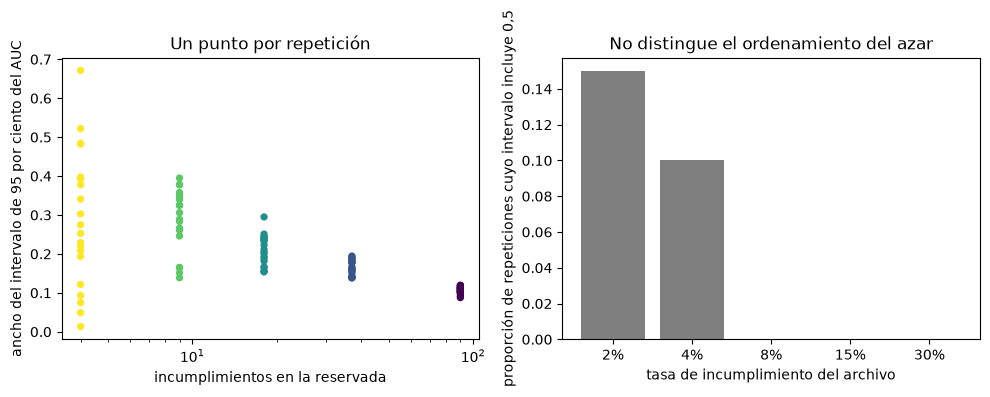

In [20]:
# Dibuja el intervalo del AUC de cada repetición frente a los incumplimientos de su reservada y la proporción con azar
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.scatter(
    runs["incumplimientos reservada"], runs["intervalo del auc"], c=-np.log10(runs["prevalencia"]), cmap="viridis", s=18
)
left.set_xscale("log")
left.set_xlabel("incumplimientos en la reservada")
left.set_ylabel("ancho del intervalo de 95 por ciento del AUC")
left.set_title("Un punto por repetición")
right.bar([f"{p:.0%}" for p in by_prevalence.index], by_prevalence["proporcion_con_azar"], color="tab:gray")
right.set_xlabel("tasa de incumplimiento del archivo")
right.set_ylabel("proporción de repeticiones cuyo intervalo incluye 0,5")
right.set_title("No distingue el ordenamiento del azar")
fig.tight_layout()
plt.show()

A la izquierda cada punto es una repetición, el ancho de su intervalo del AUC frente a los incumplimientos de su reservada en un eje logarítmico, coloreado por prevalencia. El ancho se lee frente a los incumplimientos, la cantidad de la que depende el intervalo, y no frente a la prevalencia. A la derecha las barras dan la proporción de repeticiones cuyo intervalo incluye 0,5: 0, 0, 0, 0,10 y 0,15 de 30 a 2 por ciento. El régimen donde el método falla es una reservada con menos de unos 10 incumplimientos, donde el intervalo mide de 0,26 a 0,30 y una repetición de cada diez, o más, no separa el AUC del azar. Entre 10 y 20 incumplimientos el AUC aún funciona, pero su intervalo mide 0,2 o más. La figura muestra solo el intervalo del AUC. Las pruebas de nivel también dependen de los incumplimientos, y la celda siguiente pregunta al motor cuántos necesita una prueba de nivel de 95 por ciento en la reservada de cada prevalencia.

In [21]:
# Los incumplimientos que necesita una prueba de nivel de 95 por ciento en cada reservada, frente a los esperados
power = []
for prevalence in prevalences:
    kept = len(good) + min(len(bad), int(round(prevalence / (1 - prevalence) * len(good))))
    holdout_size = int(round(0.3 * kept))
    needed = cal.critical_default_count(holdout_size, prevalence, q=0.95)
    expected = holdout_size * prevalence
    power.append({"prevalencia": prevalence, "registros de la reservada": holdout_size,
                  "incumplimientos esperados": round(expected, 1), "incumplimientos para objetar": needed,
                  "exceso necesario": round(needed / expected - 1, 2)})
pd.DataFrame(power)

,prevalencia,registros de la reservada,incumplimientos esperados,incumplimientos para objetar,exceso necesario
0,0.30,300,90.0,104,0.16
1,0.15,247,37.0,47,0.27
2,0.08,228,18.2,26,0.43
3,0.04,219,8.8,15,0.71
4,0.02,214,4.3,9,1.10


La fila de 30 por ciento es el archivo tal como es: 300 registros reservados, 90 incumplimientos esperados y una prueba de nivel que objeta solo desde 104, un exceso de 16 por ciento. Con 15 por ciento la reservada tiene 247 registros y la prueba necesita 47 incumplimientos donde se esperan 37 (27 por ciento más); con 8 por ciento necesita 26 donde se esperan 18,2 (43 por ciento); con 4 por ciento 15 donde 8,8 (71 por ciento); con 2 por ciento 9 donde 4,3, más del doble (110 por ciento). Una prueba de nivel pierde así su sensibilidad en el mismo régimen que el AUC: con menos de unos 10 incumplimientos esperados solo puede objetar cuando el modelo subestima el riesgo en más de la mitad, que es lo que encontró el notebook 02 con 50 tarjetas. La tabla da la sensibilidad de la prueba y no la calidad de ningún modelo. Dice que un semáforo verde del archivo de 2 por ciento es casi mudo, porque la reservada necesitaría más del doble de sus incumplimientos esperados para que el semáforo se moviera.

### Úsalo con tus propios datos

La cadena anterior toma un archivo, y tú traerás el tuyo. Cuatro cosas deben estar en su lugar, en orden. La fuente debe estar en el registro con su clase y los casos que pueden leerla. El archivo debe descargarse, para que su hash quede fijado en el manifiesto. Un lector debe llevar el formato del editor a una familia del contrato 1, `scored_sample` para un modelo de PD y `loan_panel` para los modelos de vida remanente y similares, y el caso debe declarar sus campos adicionales. Entonces la llamada es `ingest.ingest(case_id, source_id, file_name, reader, data_root=..., family=..., extra_fields=...)`, seguida de `split.stratified_split` y `evaluate.battery` como arriba. La celda siguiente declara una fuente propia dos veces, una como `derived-only` y otra como `link-only`, y pregunta al registro si un caso C99 puede leerla.

In [22]:
# Declara una fuente propia dos veces, como derived-only y como link-only, y pregunta al registro si un caso la lee
def declared(klass):
    return registry.Source(
        id="my-bank-file", name="Extracto puntuado de mi banco", publisher="mi banco", landing="https://example.org/",
        licence="Uso interno bajo el convenio de datos del banco", klass=klass, access="manual", cases=("C99",),
        unverified=(),
    )


replies = []
for klass in ("derived-only", "link-only"):
    book = {**sources, "my-bank-file": declared(klass)}
    try:
        registry.assert_case_inputs("C99", ["my-bank-file"], registry=book)
        replies.append({"clase": klass, "respuesta": "puede leerla"})
    except registry.LicenceError as refusal:
        replies.append({"clase": klass, "respuesta": str(refusal)})
pd.DataFrame(replies)

,clase,respuesta
0,derived-only,puede leerla
1,link-only,C99: my-bank-file is link-only; it may be link...


Una fuente declarada `derived-only` para el caso C99 puede leerse, y una declarada `link-only` se rechaza con el texto del paso 1: my-bank-file es link-only, se puede enlazar y nunca leer. La clase es la decisión, y sale de la licencia que tienes, no de la comodidad del proyecto. El extracto propio de un banco suele ser `derived-only`: el caso puede leerlo y publicar lo que deriva, y las filas siguen privadas. La celda arma la entrada en memoria con la clase de datos `registry.Source`. Para volverla real agregas los mismos campos a `data-pipeline/config/sources.json`, donde `registry.load` los revisa: un fragmento de licencia de al menos ocho caracteres, una página de aterrizaje y los casos. La celda siguiente arma el linaje de un documento derivado de esa fuente.

In [23]:
# Arma el linaje de un documento derivado de esa fuente: se rechaza hasta que el archivo se descarga y su hash se fija
book = {**sources, "my-bank-file": declared("derived-only")}
mine = lineage.build(
    "C99", sources=["my-bank-file"], truth_status="real-outcomes", seed=1, code_version="0.0.0", reg=book
)
try:
    lineage.assert_publishable(mine)
except registry.LicenceError as refusal:
    print("rechazado:", refusal)
print("parámetros de la llamada a ingest:", list(inspect.signature(ingest.ingest).parameters))

rechazado: C99: refused, the input my-bank-file is not in the licence manifest (fetch it with data-pipeline/fetch.py first, so its bytes are hashed and its licence recorded)
parámetros de la llamada a ingest: ['case_id', 'source_id', 'file_name', 'reader', 'data_root', 'family', 'extra_fields', 'extra_rules', 'params']


El documento se rechaza: C99 se rechaza porque la entrada my-bank-file no está en el manifiesto de licencias, y el mensaje nombra el remedio, `data-pipeline/fetch.py`, para que los bytes queden con hash y la licencia registrada. El registro dice que la fuente puede leerse, y aun así el linaje no puede publicarse hasta que el archivo se haya descargado y su entrada escrito. La última línea lista los nueve parámetros de la llamada a ingest: el caso y la fuente, el nombre del archivo, el lector, la raíz de datos, la familia, los campos y reglas adicionales y los parámetros del conjunto de datos. El lector es la parte que escribes tú, una función de la ruta del archivo a una lista de diccionarios que el contrato 1 interpreta luego según su tipo. Nunca hagas que limpie los datos: un valor reparado es un número que el validador no vio. La última celda reúne las revisiones que se hacen tras una corrida.

In [24]:
# Las revisiones que se hacen tras correr un archivo propio, leídas aquí de la corrida alemana confirmada y su muestra
counts = report.counts()
checks = [
    ("el hash del archivo es el fijado", f"fijado {pinned['sha256'][:16]}", "True"),
    ("filas aceptadas por el contrato 1", f"{counts['accepted']} de {counts['input']} (la muestra)",
     "todas, o cada rechazo dicho"),
    ("columnas que ignoró el contrato 1", ", ".join(report.ignored_columns) or "ninguna",
     "solo campos que decidiste no usar"),
    ("incumplimientos en la reservada", summary["holdout"]["defaults"], "varias decenas; bajo 10 el AUC dice poco"),
    ("filas de la batería en estado error", sum(row["light"] == "error" for row in rows), "0"),
    ("filas de la batería sin evaluar", sum(row["light"] == "not_evaluated" for row in rows), "solo pruebas sin corte"),
]
pd.DataFrame(checks, columns=["revisión", "esta corrida", "lo que quieres"])

,revisión,esta corrida,lo que quieres
0,el hash del archivo es el fijado,fijado e12d9d5def6845c0,True
1,filas aceptadas por el contrato 1,50 de 50 (la muestra),"todas, o cada rechazo dicho"
2,columnas que ignoró el contrato 1,ninguna,solo campos que decidiste no usar
3,incumplimientos en la reservada,90,varias decenas; bajo 10 el AUC dice poco
4,filas de la batería en estado error,0,0
5,filas de la batería sin evaluar,4,solo pruebas sin corte


La tabla es la lista que se llena tras cualquier corrida con un archivo propio, aquí leída del caso alemán confirmado. La línea del hash muestra la fijación con la que comparar, que empieza con `e12d9d5def6845c0`; el contrato 1 aceptó 50 de 50 registros de la muestra y no ignoró ninguna columna; la reservada tiene 90 incumplimientos; ninguna fila de la batería está en el estado `error`; cuatro filas están sin evaluar, las pruebas sin puntos de corte. Cada línea tiene un valor que te dice que te detengas: un hash que difiere, una fila rechazada que no puedes explicar, una columna ignorada que querías usar, menos de unos 10 incumplimientos en la reservada (el barrido de arriba), una fila de error, o una fila sin evaluar de una prueba que la política debería colorear. La tabla no puede revisar si el archivo es el correcto para la pregunta, que es el juicio del lector.

## Resultados

**Respuesta:** Cada etapa da una garantía y cada una puede leerse en un documento confirmado. Con el caso alemán, el registro lista `uci-german` para C01 y lo rechaza para C05, el manifiesto fija el archivo con el hash `e12d9d5def6845c0`, el contrato 1 acepta los 50 solicitantes de la muestra confirmada, la partición estratificada pone 168, 42 y 90 incumplimientos en 560, 140 y 300 registros, como la partición confirmada, y la batería confirmada tiene 24 filas, 20 verdes y 4 sin evaluar. La última garantía pierde valor a medida que la reservada pierde incumplimientos: con 9, el intervalo mediano del AUC mide 0,297 de ancho, frente a 0,108 con 90, y con 4 la relación entre ancho e incumplimientos ya no se cumple.

- **Licencia.** El registro tiene 58 fuentes, 41 de ellas legibles, y el manifiesto fija cada archivo con un hash; la etapa rechaza un archivo cuyo resumen difiere de la fijación y dice cómo descargar uno ausente. El linaje armado con ellos es igual a la procedencia del gemelo alemán confirmado, y la tabla de licencias cubre el código.
- **Contrato.** El contrato 1 tiene ocho familias declaradas en documentos confirmados. Aceptó todos los registros de la muestra confirmada; revisa rangos y tipos y nunca unidades, como mostró el notebook 04.
- **Partición.** Una reservada estratificada conserva la tasa de incumplimiento exacta, donde una aleatoria se mueve con una desviación estándar de 0,0441 con 10 por ciento reservado.
- **Fila de prueba.** Cada fila tiene las 18 claves del contrato `test-result`, de modo que un semáforo puede leerse de nuevo bajo otra política; el scorecard confirmado no tiene ninguna fila ámbar entre 24, y la etapa con 25 solicitantes da el mismo AUC que una llamada directa al motor.
- **Dónde se quiebra.** El ancho del intervalo del AUC sigue $c/\sqrt{d_h}$ con $c$ cerca de 1 de 90 a 9 incumplimientos en la reservada, y bajo unos 10 se ensancha y se vuelve inestable. Una prueba de nivel necesita 104 incumplimientos en la reservada de 300 registros, 16 por ciento sobre los 90 esperados, y 9 en la reservada del archivo de 2 por ciento, 110 por ciento sobre los 4,3 esperados.
- **Tus propios datos.** Registra la fuente con la clase que respalda tu licencia, descárgala para que el hash quede fijado, escribe un lector y lee las seis revisiones de la última tabla antes de cualquier valor p.

Lo que este notebook no hace: no lee el archivo alemán con licencia ni el de Taiwán, que necesita un lector que el entorno de los notebooks no fija; quien tiene la licencia vuelve a correr los comandos de la sección Datos. No ajusta ningún modelo: las PD son las del scorecard confirmado, y la escalera del producto la construye el tema 02.

## Resumen

- Un caso son cuatro etapas y cuatro garantías: el registro y el hash fijado dicen qué puede leerse, el contrato 1 dice qué registros entran, la partición estratificada mantiene honesta a la reservada y la etapa de evaluación devuelve filas del contrato `test-result`.
- El registro tiene 58 fuentes por clase y el manifiesto fija cada archivo con SHA-256; el linaje de un documento es igual a la clase del registro y al hash del manifiesto, y se rechaza un documento con una entrada sin descargar o solo enlazable.
- Una reservada estratificada fija su conteo de incumplimientos; una aleatoria tiene una desviación estándar de 0,0624 a 0,0139 para reservadas de 5 a 50 por ciento, como dice la fórmula hipergeométrica.
- El scorecard confirmado no tiene ningún ámbar entre sus 24 filas, y las pruebas sin puntos de corte devuelven `not_evaluated`.
- El intervalo del AUC sigue $c/\sqrt{d_h}$ con $c$ cerca de 1 hasta 9 incumplimientos en la reservada, y bajo unos 10 se ensancha y se vuelve inestable.

**Qué probar a continuación.** Adelgaza los incumplimientos a 12 por ciento y a 6 por ciento y lee de nuevo la lista de revisión, luego escribe un lector para un CSV tuyo, regístralo en una copia del registro y corre las tres llamadas de la sección sobre tus propios datos. Continúa con el tema 02, que construye los modelos que valida esta batería.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- NIST (2015), Secure Hash Standard (SHS), FIPS PUB 180-4. https://doi.org/10.6028/NIST.FIPS.180-4
- scikit-learn, `train_test_split`, la partición estratificada detrás de la etapa. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- Creative Commons, Attribution 4.0 International, la licencia de los datos de German Credit. https://creativecommons.org/licenses/by/4.0/
- Distribución hipergeométrica, la varianza de un sorteo sin reemplazo. https://en.wikipedia.org/wiki/Hypergeometric_distribution
- riskvalidation 1.1.0, la versión del motor que fijan los notebooks. https://pypi.org/project/riskvalidation/1.1.0/
- Este repositorio: `docs/contracts/catalog.md` (los contratos que se leen aquí) y `docs/guides/02_validate-your-own-model.md`.